# Task 13, Notebook 07: Attrition v2, data, leakage and baseline

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 13: Attrition model v2: beat the baseline honestly  
**Objective:** Re-audit the attrition data and leakage controls, reuse the Phase 1 pipeline and folds, and fix the baseline v2 must beat.  
**Workflow stages covered in this notebook:** 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


## Stage 1: Business Understanding

*What this stage is for:* Who needs this result and what decision it supports.

Earlier help for people who may leave only works if the prediction is real. A model that looks better because of leakage hurts HR twice: it wastes effort and hides who actually needs support. Teams re-check leakage whenever a score jumps.

## Stage 2: Problem Definition

*What this stage is for:* The exact prediction, ranking or measurement problem, its inputs and its output.

**Binary classification:** will the employee leave within 12 months of the observation date? **Inputs:** HR, pay and 3-month attendance/payroll aggregates known at the observation date. **Output:** a probability per employee, later explained in Task 14. v2 means a gradient-boosting based model.

## Stage 3: Objective and Success Criteria

*What this stage is for:* What number or evidence shows the task is done well, decided before looking at results.

Pass marks, fixed in the config before any result: the improvement over the Task 3 baseline is called *real* only if the bootstrap 95% interval of the paired fold difference in ROC-AUC is above zero; probabilities must be calibrated (ECE at most 0.05); no single feature may predict the target suspiciously well (AUC at most 0.80).

In [2]:
import joblib
from cortexhr.phase3.attrition import v2 as V, train as TR
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr import config as C, features as F
CFG_A = CFG['attrition']['success_criteria']
pd.Series(CFG_A, name='threshold').to_frame()

                                        threshold
gain_is_real_if_bootstrap_ci_low_above       0.00
max_expected_calibration_error               0.05
max_leakage_single_feature_auc               0.80

In [3]:
d = V.load_training(); X, y, Xtr, Xte, ytr, yte, folds, dfm = d['X'], d['y'], d['Xtr'], d['Xte'], d['ytr'], d['yte'], d['folds'], d['df']
bench = read_csv('baseline_benchmarks'); print('model frame:', dfm.shape, '| inputs:', X.shape[1], '| train/test:', len(Xtr), '/', len(Xte), '| folds:', len(folds), '| base rate: %.3f' % y.mean())

model frame: (2383, 56) | inputs: 43 | train/test: 1906 / 477 | folds: 5 | base rate: 0.146


## Stage 4: Dataset Discovery

*What this stage is for:* Which files exist, how they relate, and which are authoritative.

Tables: `attrition_dataset` (2,389 employee snapshots), the attendance and payroll monthly feature tables (joined with a cut-off so no future month is used), `baseline_benchmarks` (the programme's reference numbers) and, for Task 14, `attrition_scoring_2026`.

## Stage 5: Data Loading

*What this stage is for:* Load with the project helpers and check the load is complete.

Loaded through the Phase 1 loader `cortexhr.runs.load_model_frame`: exact duplicates dropped, monthly aggregates joined cut-off-safe, stratified 80/20 split, 5 stratified folds with seed 42, identical to Task 3.

In [4]:
d['join_report']

{'rows_before_join': 2383, 'rows_after_join': 2383, 'cardinality': 'attrition(1) -> aggregates(1), validated one_to_one', 'attendance_matched_rows': 383, 'payroll_matched_rows': 383, 'unmatched_rows_attendance': 2000, 'unmatched_rows_payroll': 2000, 'rows_dropped': 0, 'window_months': 3, 'temporal_cutoff': 'only complete months with month_end <= observation_date; last `window` such months', 'payroll_exact_duplicates_removed': 15, 'rows_before': 2389, 'exact_duplicates_dropped': 6, 'rows_after': 2383}

## Stage 6: Dataset Structure and Shape

*What this stage is for:* Rows, columns, keys and grain of each table.

In [5]:
pd.Series({'raw rows': d['raw'].shape[0], 'rows after removing exact duplicates': dfm.shape[0], 'model inputs': X.shape[1], 'train rows': len(Xtr), 'test rows': len(Xte), 'leavers in train': int(ytr.sum()), 'leavers in test': int(yte.sum())}, name='count').to_frame()

                                      count
raw rows                               2389
rows after removing exact duplicates   2383
model inputs                             43
train rows                             1906
test rows                               477
leavers in train                        279
leavers in test                          70

## Stage 7: Data Dictionary and Schema Understanding

*What this stage is for:* What each column means, from the supplied dictionary and from inspection.

In [6]:
read_csv('data_dictionary').query("sheet == 'attrition_dataset'")[['column', 'data_type', 'description']].head(30)

                             column data_type                                                                             description
0                            row_id   integer                                                                Row number in the sheet.
1                       employee_id      text       Unique employee code (EMP-0001 ...). Same code in every table and every workbook.
2                  observation_date      date                       Date the features were measured (30 Sep 2025 for real snapshots).
3                     department_id      text                             Department code (D00 Executive ... D10 Legal & Compliance).
4                           role_id      text                                                     Job role code from the roles table.
5                         job_level   integer                                           Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).
6                     work_location      text                 

## Stage 8: Data Type Inspection

*What this stage is for:* Check every column has the type it should have.

In [7]:
pd.Series(X.dtypes.astype(str).map(lambda t: 'numeric' if t.startswith(('int', 'float')) else 'text/category')).value_counts().to_frame('inputs')

               inputs
numeric            37
text/category       6

## Stage 9: Data Quality Assessment

*What this stage is for:* A one-page quality profile before any modelling.

In [8]:
profile(X).sort_values('missing_pct', ascending=False).head(12)

                               dtype  missing  missing_pct  unique
att_late_arrivals_sum_3m     float64     2000        83.93      19
att_unpaid_absence_sum_3m    float64     2000        83.93      16
att_attendance_rate_mean_3m  float64     2000        83.93     148
pay_lop_days_sum_3m          float64     2000        83.93      12
pay_overtime_pay_mean_3m     float64     2000        83.93      58
pay_variable_share_3m        float64     2000        83.93      46
pay_net_to_gross_3m          float64     2000        83.93     382
pay_variable_pay_mean_3m     float64     2000        83.93      42
att_half_days_sum_3m         float64     2000        83.93       5
att_wfh_share_3m             float64     2000        83.93     190
att_avg_hours_mean_3m        float64     2000        83.93     280
att_overtime_mean_3m         float64     2000        83.93      45

## Stage 10: Missing Value Analysis

*What this stage is for:* Where values are missing, how much, and why that may be.

Missing is informative here: `months_since_last_promotion` is empty for people never promoted; engagement and performance are missing for people who were not rated; monthly aggregates exist only for part of the history. The pipeline imputes with training statistics and adds missing-indicator columns.

In [9]:
m = X.isna().mean().sort_values(ascending=False); print(m[m > 0].round(3).to_dict())
miss = pd.DataFrame({'missing_share': X.isna().mean(), 'leave_rate_if_missing': {c: y[X[c].isna()].mean() if X[c].isna().any() else np.nan for c in X.columns}}).dropna().sort_values('missing_share', ascending=False).head(6).round(3); miss

{'att_late_arrivals_sum_3m': 0.839, 'att_unpaid_absence_sum_3m': 0.839, 'att_attendance_rate_mean_3m': 0.839, 'pay_lop_days_sum_3m': 0.839, 'pay_overtime_pay_mean_3m': 0.839, 'pay_variable_share_3m': 0.839, 'pay_net_to_gross_3m': 0.839, 'pay_variable_pay_mean_3m': 0.839, 'att_half_days_sum_3m': 0.839, 'att_wfh_share_3m': 0.839, 'att_avg_hours_mean_3m': 0.839, 'att_overtime_mean_3m': 0.839, 'months_since_last_promotion': 0.61, 'last_engagement_score': 0.222, 'last_raise_pct': 0.084, 'last_performance_rating': 0.076, 'commute_distance_km': 0.023, 'highest_education': 0.006}


                             missing_share  leave_rate_if_missing
att_late_arrivals_sum_3m             0.839                   0.15
att_overtime_mean_3m                 0.839                   0.15
pay_lop_days_sum_3m                  0.839                   0.15
pay_overtime_pay_mean_3m             0.839                   0.15
att_unpaid_absence_sum_3m            0.839                   0.15
att_attendance_rate_mean_3m          0.839                   0.15

## Stage 11: Duplicate Analysis

*What this stage is for:* Exact and near duplicates of rows, keys and texts.

In [10]:
print('exact duplicate rows in the raw file:', int(d['raw'].duplicated().sum()), '| after cleaning:', int(dfm.duplicated(subset=[c for c in dfm.columns if c != 'row_id']).sum()), '| employee_id unique:', dfm.employee_id.is_unique)

exact duplicate rows in the raw file: 0 | after cleaning: 0 | employee_id unique: True


## Stage 12: Outlier Detection and Investigation

*What this stage is for:* Unusual values: are they errors or real?

In [11]:
num = X.select_dtypes('number'); rows = []
for c in ['tenure_months', 'commute_distance_km', 'annual_fixed_pay', 'training_hours_12m', 'avg_overtime_hours_per_month_3m', 'paid_leave_days_6m']:
    q1, q3 = num[c].quantile([.25, .75]); i = q3 - q1; o = ((num[c] < q1 - 1.5 * i) | (num[c] > q3 + 1.5 * i)); rows.append({'feature': c, 'IQR outliers': int(o.sum()), 'share': round(o.mean(), 3), 'max': num[c].max(), 'leave_rate_of_outliers': round(y[o].mean(), 3) if o.any() else np.nan})
pd.DataFrame(rows)

                           feature  IQR outliers  share         max  leave_rate_of_outliers
0                    tenure_months            73  0.031       164.0                   0.110
1              commute_distance_km           141  0.059        65.0                   0.227
2                 annual_fixed_pay            93  0.039  18671760.0                   0.118
3               training_hours_12m            99  0.042       140.0                   0.101
4  avg_overtime_hours_per_month_3m           445  0.187        50.0                   0.173
5               paid_leave_days_6m            23  0.010        51.0                   0.043

## Stage 13: Invalid and Inconsistent Value Detection

*What this stage is for:* Impossible values, broken links between tables, label contradictions.

Impossible values. The Phase 1 cleaning step already sets impossible values to missing and clips rates to 0..1; here they are counted before cleaning.

In [12]:
raw = dfm; checks = {'attendance_rate_3m outside 0..1': int(((raw.attendance_rate_3m < 0) | (raw.attendance_rate_3m > 1)).sum()), 'att_wfh_share_3m above 1 (raw monthly aggregate)': int((raw.att_wfh_share_3m > 1).sum()),
 'comp_ratio outside 0.2..2.5': int(((raw.comp_ratio < .2) | (raw.comp_ratio > 2.5)).sum()), 'negative tenure': int((raw.tenure_months < 0).sum()), 'annual_fixed_pay <= 0': int((raw.annual_fixed_pay <= 0).sum())}
print(checks); print('after the pipeline cleaning step: rates are clipped to [0, 1] (stateless, no learned values)')

{'attendance_rate_3m outside 0..1': 2, 'att_wfh_share_3m above 1 (raw monthly aggregate)': 1, 'comp_ratio outside 0.2..2.5': 0, 'negative tenure': 4, 'annual_fixed_pay <= 0': 0}
after the pipeline cleaning step: rates are clipped to [0, 1] (stateless, no learned values)


## Stage 14: Exploratory Data Analysis (EDA)

*What this stage is for:* Look at the data before modelling.

In [13]:
print('base rate of leaving within 12 months: %.3f (%d of %d)' % (y.mean(), y.sum(), len(y))); dfm.groupby('department_id').left_within_12m.agg(['mean', 'size']).round(3).sort_values('mean', ascending=False).head(6)

base rate of leaving within 12 months: 0.146 (349 of 2383)


                mean  size
department_id             
D06            0.211   323
D09            0.171   228
D02            0.143   161
D04            0.139   266
D01            0.136   806
D08            0.135   111

## Stage 15: Univariate Analysis

*What this stage is for:* One variable at a time.

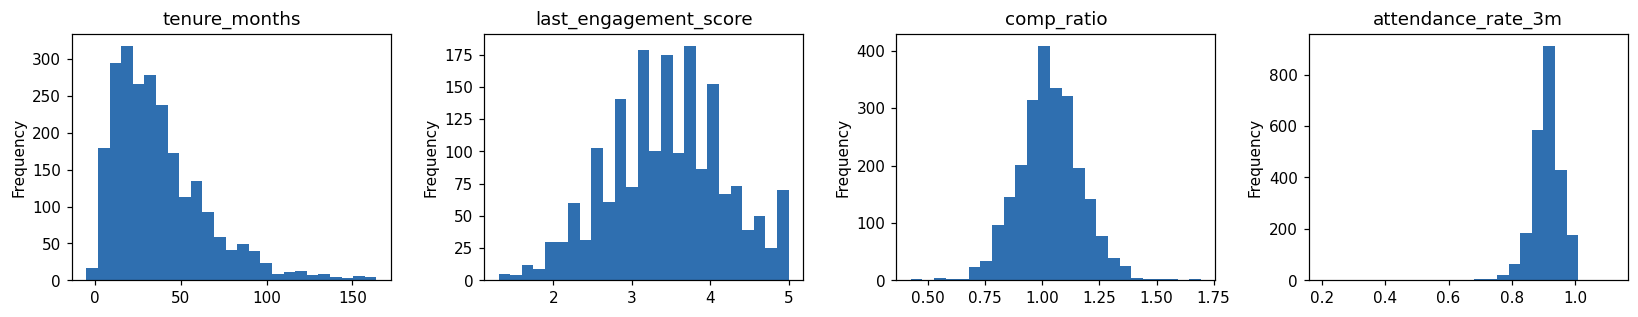

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, c in zip(ax, ['tenure_months', 'last_engagement_score', 'comp_ratio', 'attendance_rate_3m']): X[c].plot.hist(ax=a, bins=25, color='#2f6fb0'); a.set_title(c)
plt.tight_layout()

## Stage 16: Bivariate Analysis

*What this stage is for:* Two variables together, especially against the target or label.

Leave rate against the main drivers, by quantile bins (a bivariate view, not a causal claim).

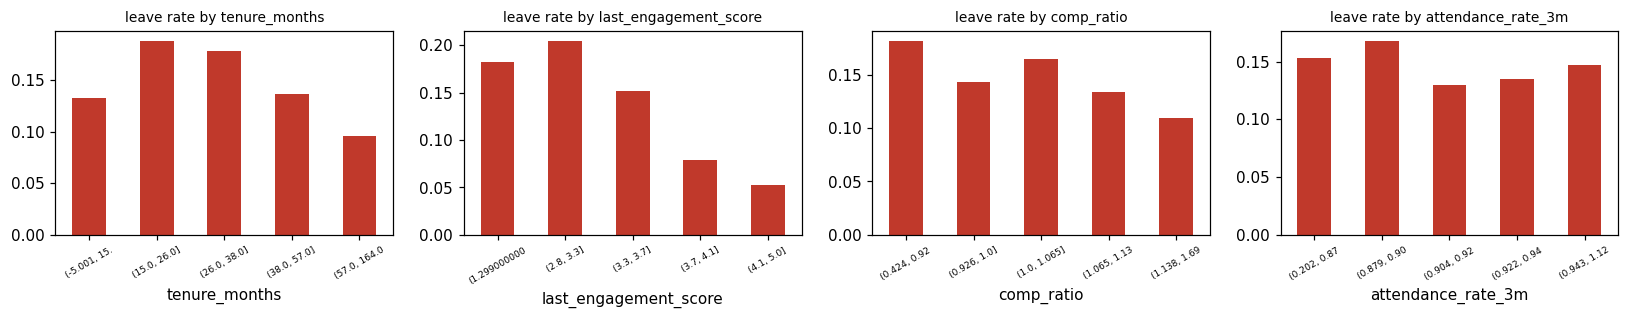

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3)); 
for a, c in zip(ax, ['tenure_months', 'last_engagement_score', 'comp_ratio', 'attendance_rate_3m']):
    b = pd.qcut(X[c], 5, duplicates='drop'); r = y.groupby(b, observed=True).mean(); r.plot.bar(ax=a, color='#c0392b'); a.set_title('leave rate by ' + c, fontsize=9); a.set_xticklabels([str(i)[:12] for i in r.index], rotation=30, fontsize=6)
plt.tight_layout()

## Stage 17: Multivariate Analysis

*What this stage is for:* Several variables together: correlation, interaction, redundancy.

Redundant inputs: the 3-month attendance numbers appear twice (HR snapshot and monthly table). This is why Task 14 explains in *groups*.

In [16]:
num = X.select_dtypes('number'); cm = num.corr(method='spearman').abs(); cm = cm.mask(np.eye(len(cm), dtype=bool), 0)
pairs_ = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().sort_values(ascending=False).head(8).round(3); pairs_.to_frame('|spearman|')

                                                          |spearman|
avg_overtime_hours_per_month_3m att_overtime_mean_3m           1.000
att_overtime_mean_3m            pay_overtime_pay_mean_3m       0.999
pay_variable_pay_mean_3m        pay_variable_share_3m          0.999
avg_overtime_hours_per_month_3m pay_overtime_pay_mean_3m       0.999
wfh_share_3m                    att_wfh_share_3m               0.982
late_arrivals_3m                att_late_arrivals_sum_3m       0.965
tenure_months                   raises_received                0.937
avg_hours_worked_3m             att_avg_hours_mean_3m          0.930

## Stage 18: Target or Label Analysis

*What this stage is for:* How the target or human label is distributed and how reliable it is.

In [17]:
print('target = left_within_12m. rate overall %.3f | train %.3f | test %.3f' % (y.mean(), ytr.mean(), yte.mean()), '| the split keeps the rate equal (stratified).'); print('Always-stay baseline accuracy: %.3f but it finds 0 leavers, which is why PR-AUC and recall are reported.' % (1 - y.mean()))

target = left_within_12m. rate overall 0.146 | train 0.146 | test 0.147 | the split keeps the rate equal (stratified).
Always-stay baseline accuracy: 0.854 but it finds 0 leavers, which is why PR-AUC and recall are reported.


## Stage 19: Data Leakage Investigation

*What this stage is for:* Anything that carries the answer or protected information into the model.

Leakage checks. (1) the exit columns exist only after someone leaves; (2) the monthly aggregates use only months before the observation date; (3) no single input predicts the target too well; (4) the leaky model in the benchmark file shows what leakage looks like.

In [18]:
print('columns excluded as inputs (Phase 1 audit, kept unchanged):', C.FORBIDDEN_AS_INPUT)
print('any excluded column present among the inputs:', [c for c in C.FORBIDDEN_AS_INPUT if c in X.columns])
print(bench[bench.model.str.contains('LEAKY')][['model', 'roc_auc_mean', 'comment']].to_string(index=False))

columns excluded as inputs (Phase 1 audit, kept unchanged): ['left_within_12m', 'row_id', 'employee_id', 'observation_date', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'voluntary_left_within_12m', 'source']
any excluded column present among the inputs: []
                                            model  roc_auc_mean                                   comment
LEAKY Logistic Regression (adds exit information)           1.0 Too good to be true: this is data leakage


In [19]:
from sklearn.metrics import roc_auc_score
rows = []
for c in X.columns:
    s = X[c]
    if s.dtype.kind in 'if': v = s.fillna(s.median())
    else: v = s.map(y.groupby(s).mean()).fillna(y.mean())        # target mean encoding (diagnostic only)
    a = roc_auc_score(y, v); rows.append({'feature': c, 'single_feature_auc': max(a, 1 - a)})
sf = pd.DataFrame(rows).sort_values('single_feature_auc', ascending=False); print('max single-feature AUC: %.3f (limit %.2f) -> %s' % (sf.single_feature_auc.max(), CFG_A['max_leakage_single_feature_auc'], 'OK' if sf.single_feature_auc.max() <= CFG_A['max_leakage_single_feature_auc'] else 'SUSPICIOUS')); sf.head(6).round(3)

max single-feature AUC: 0.619 (limit 0.80) -> OK


                    feature  single_feature_auc
26                  role_id               0.619
14    last_engagement_score               0.612
9   months_since_last_raise               0.599
30        highest_education               0.595
15      manager_changes_12m               0.572
28                work_mode               0.563

Note: the target-mean encoding of `role_id` and `highest_education` inflates their diagnostic AUC (many categories, computed on all rows) so it is an upper bound used only to hunt for leakage, never a model result.

## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

Reused from Phase 1: stateless cleaning, derived features (pay versus department median, raise recency, overtime flag, missing indicators), scaling and one-hot encoding. Nothing new is learned outside the training folds.

In [20]:
pipe = F.build_pipeline(True).fit(Xtr, ytr); Z = pipe.transform(Xte); print('raw inputs:', X.shape[1], '-> model-ready columns:', Z.shape[1]); print([s[0] for s in pipe.steps])

raw inputs: 43 -> model-ready columns: 142
['clean', 'derive', 'prep']


## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Allowed inputs, excluded inputs, and inputs that need careful wording because they can act as proxies.

In [21]:
protected = [c for c in X.columns if any(k in c.lower() for k in ('gender', 'sex', 'age_', 'religion', 'marital', 'caste', 'disab'))]
print('protected attributes among the inputs:', protected or 'none'); print('proxy-risk inputs kept (flagged for explanation wording in Task 14): total_experience_years (age proxy), highest_education, work_location, tenure_months (new joiners)')

protected attributes among the inputs: none
proxy-risk inputs kept (flagged for explanation wording in Task 14): total_experience_years (age proxy), highest_education, work_location, tenure_months (new joiners)


## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Preprocessing is inside the sklearn pipeline, so it is refit on the training part of every fold. Demonstration: the imputation value learned on training data differs from the value on all data.

In [22]:
print('median engagement: train part %.3f | all rows %.3f -> statistics are learned only from the training part' % (Xtr.last_engagement_score.median(), X.last_engagement_score.median()))

median engagement: train part 3.500 | all rows 3.500 -> statistics are learned only from the training part


## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

80% training (1,906 rows) / 20% test (477 rows), stratified, seed 42; 5-fold stratified cross-validation **inside the training part**, the same folds as Task 3. The test set is used once, at the end.

In [23]:
pd.DataFrame([{'fold': i, 'train': len(a), 'validation': len(b), 'leavers_in_validation': int(ytr.iloc[b].sum()), 'rate': round(ytr.iloc[b].mean(), 3)} for i, (a, b) in enumerate(folds)])

   fold  train  validation  leavers_in_validation   rate
0     0   1524         382                     56  0.147
1     1   1525         381                     55  0.144
2     2   1525         381                     56  0.147
3     3   1525         381                     56  0.147
4     4   1525         381                     56  0.147

## Stage 24: Baseline Establishment

*What this stage is for:* The simple method every model must beat.

The baseline v2 must beat: Phase 1 logistic regression (balanced classes) on the same folds, next to the programme's reference numbers.

In [24]:
lr = V.baseline_models()['Logistic Regression (balanced)']; ft = V.fold_table(lr, Xtr, ytr, folds, 'Logistic Regression (balanced)')
mine = V.summarise(ft)[['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'precision_mean', 'recall_mean']]
ref = bench[bench.model.str.startswith('Logistic Regression (class')][['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'precision_mean', 'recall_mean']]
pd.concat([mine.assign(source='this repo, same folds'), ref.assign(source='programme reference')]).round(3)

                                         model  roc_auc_mean  roc_auc_sd  pr_auc_mean  precision_mean  recall_mean                 source
0               Logistic Regression (balanced)         0.709       0.021        0.325           0.262        0.584  this repo, same folds
1  Logistic Regression (class_weight=balanced)         0.713       0.010        0.332           0.260        0.630    programme reference